# 04 - Models and hyperparameter tuning

Goal: compare **every model family allowed by the competition rules** on the features of `03_features.ipynb`,
tune each of them with a randomized / grid search in cross-validation, build ensembles on top of the best ones,
and end with a **summary table of the best models and their best parameters**.

Plan:
1. Candidate models allowed by the rules.
2. Screening with default parameters.
3. Hyperparameter search (RandomizedSearchCV / GridSearchCV, 5-fold, seed 42).
4. Repeated CV of the tuned models (seeds 42, 7, 123) on all features and on the robust subset.
5. Stress test: what happens if P2's KOs are recorded differently on the final evaluation set.
6. Ensembles: soft voting and stacking of the top models.
7. Optional nested CV for an unbiased estimate of the top models.
8. Summary table.

> Everything uses the training set only. The model code lives in `src/models.py` (models and search spaces)
> and `src/validation.py` (CV and stress test). Outputs are saved in `data/processed/models/`.
>
> This notebook is heavy (hundreds of model fits). Adjust the run configuration in section 0 to the machine.

## 0. Setup and run configuration

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

# Silence convergence / future warnings, also in the joblib worker processes
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models import best_from_search, get_model_specs, params_to_json, params_to_text, tune, with_params
from src.validation import REPEAT_SEEDS, SEED, cv_scores, repeated_cv, stress_test

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 250)
pd.set_option('display.width', 250)

In [14]:
# --- Run configuration (adjust to the machine) ---
N_JOBS = -1              # parallel folds / candidates (all cores)
N_ITER_SCALE = 1.0       # multiplies the random-search candidates of every model (e.g. 0.3 for a quick run)
MODELS_TO_RUN = None     # None = all models, or a list of names, e.g. ['logreg', 'lightgbm']
SKIP_MODELS = []         # e.g. ['gradient_boosting', 'svm_rbf'] if they are too slow
TOP_K = 4                # tuned models combined in the ensembles
RUN_STACKING = True
RUN_NESTED_CV = True    # unbiased estimate of the top 3 models (expensive: a full search per outer fold)

PROC = ROOT / 'data' / 'processed'
OUT = PROC / 'models'
OUT.mkdir(parents=True, exist_ok=True)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [3]:
features = pd.read_pickle(PROC / 'features_train.pkl')
with open(PROC / 'feature_groups.json') as f:
    groups = json.load(f)

y = features.pop('player_won')
CAT = groups['species_cat']          # not used: species target encoding added nothing (experiment 03)
NUM = [c for c in features.columns if c not in CAT]
ROBUST = groups['robust']
X_all, X_robust = features[NUM], features[ROBUST]
print(f'train: {len(y):,} battles | all features: {X_all.shape[1]} | robust subset: {X_robust.shape[1]}')

specs = get_model_specs()
names = [n for n in (MODELS_TO_RUN or list(specs)) if n not in SKIP_MODELS]
print('models:', names)

train: 10,000 battles | all features: 155 | robust subset: 145
models: ['logreg', 'ridge', 'linear_svm', 'lda', 'qda', 'gaussian_nb', 'knn', 'svm_rbf', 'decision_tree', 'random_forest', 'extra_trees', 'adaboost', 'gradient_boosting', 'hist_gb', 'lightgbm', 'xgboost', 'catboost']


## 1. Candidate models allowed by the rules

Only classical machine learning is allowed. **Excluded**: neural networks (including `MLPClassifier`) and
pretrained models (e.g. TabPFN).

| Family | Models | Preprocessing in the pipeline |
|---|---|---|
| Linear | Logistic Regression, Ridge classifier, linear SVM | median imputation + scaling |
| Discriminant analysis | LDA (with shrinkage), QDA (with regularisation) | median imputation + scaling |
| Naive Bayes | Gaussian NB | median imputation + scaling |
| Neighbours | k-NN | median imputation + scaling |
| Kernel | SVM with RBF kernel | median imputation + scaling |
| Trees | Decision tree | median imputation |
| Bagging | Random Forest, Extra Trees | median imputation |
| Boosting | AdaBoost, Gradient Boosting, HistGradientBoosting, LightGBM, XGBoost, CatBoost | imputation (sklearn) or native NaN handling |
| Ensembles | soft voting, stacking with a logistic meta-model | built from the tuned models |

Search spaces are defined in `src/models.py`: grid search for small spaces (LDA, QDA, NB, k-NN),
randomized search for the others.

In [4]:
overview = pd.DataFrame([{'model': s.name, 'family': s.family, 'search': s.search,
                          'candidates': (s.n_iter if s.search == 'random' else 'full grid'),
                          'parameters searched': ', '.join(k.replace('model__', '') for k in s.space)}
                         for s in specs.values() if s.name in names])
overview

,model,family,search,candidates,parameters searched
0,logreg,linear,random,25,C
1,ridge,linear,random,25,alpha
2,linear_svm,svm,random,25,C
3,lda,discriminant,grid,full grid,shrinkage
4,qda,discriminant,grid,full grid,reg_param
5,gaussian_nb,naive_bayes,grid,full grid,var_smoothing
6,knn,neighbors,grid,full grid,"n_neighbors, weights, p"
7,svm_rbf,svm,random,20,"C, gamma"
8,decision_tree,tree,random,40,"max_depth, min_samples_leaf, criterion, ccp_alpha"
9,random_forest,bagging,random,25,"n_estimators, max_depth, min_samples_leaf, max_features"


## 2. Screening with default parameters

5-fold CV (seed 42) with the default parameters of each model, as a reference for the tuning.

In [5]:
screen_rows = []
for name in names:
    t0 = time.time()
    try:
        s = cv_scores(specs[name].estimator, X_all, y)
    except Exception as e:
        print(f'{name:18s} FAILED: {e}')
        continue
    elapsed = time.time() - t0
    screen_rows.append({'model': name, 'family': specs[name].family, 'cv_mean': s.mean(), 'cv_std': s.std(), 'time_s': elapsed})
    print(f'{name:18s} {s.mean():.4f} ± {s.std():.4f}  ({elapsed:6.1f}s)')

screen = pd.DataFrame(screen_rows).sort_values('cv_mean', ascending=False).reset_index(drop=True)
screen.to_csv(OUT / 'screening.csv', index=False)
screen.round(4)

logreg             0.6764 ± 0.0072  (   2.0s)
ridge              0.6773 ± 0.0075  (   1.5s)
linear_svm         0.6778 ± 0.0071  (   1.9s)
lda                0.6774 ± 0.0074  (   1.3s)
qda                FAILED: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "..\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "..\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "..\.venv\Lib\site-packages\sklearn\pipeline.py", line 645, in fit
    self._final_estimator.fit(Xt, y, **last_ste

,model,family,cv_mean,cv_std,time_s
0,catboost,boosting,0.6787,0.0041,18.5852
1,linear_svm,svm,0.6778,0.0071,1.8967
2,lda,discriminant,0.6774,0.0074,1.2940
3,ridge,linear,0.6773,0.0075,1.4791
4,logreg,linear,0.6764,0.0072,1.9525
5,gradient_boosting,boosting,0.6761,0.0027,6.8388
6,svm_rbf,svm,0.6736,0.0105,3.7172
7,lightgbm,boosting,0.6713,0.0063,0.5315
8,hist_gb,boosting,0.6675,0.0045,1.3011
9,random_forest,bagging,0.6651,0.0032,2.1237


## 3. Hyperparameter search

For every model: randomized search (or grid search for small spaces) with 5-fold stratified CV, seed 42,
accuracy as the metric. All preprocessing is inside the pipeline, so it is refitted in each fold.
The full `cv_results_` of every search is saved to `data/processed/models/search_<model>.csv`.

> The best score of a search is **optimistic** (it is the maximum over many candidates on the same folds):
> the models are compared with the repeated CV of section 4, and optionally with nested CV (section 7).

In [6]:
tuned = {}
t_start = time.time()
for name in names:
    spec = specs[name]
    t0 = time.time()
    try:
        search = tune(spec, X_all, y, CV, n_iter_scale=N_ITER_SCALE, n_jobs=N_JOBS)
    except Exception as e:
        print(f'{name:18s} search FAILED: {e}')
        continue
    params, mean, std = best_from_search(search)
    n_cand = len(search.cv_results_['params'])
    elapsed = time.time() - t0
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'search_{name}.csv', index=False)
    tuned[name] = {'params': params, 'tune_mean': mean, 'tune_std': std, 'n_candidates': n_cand, 'time_s': elapsed}
    print(f'{name:18s} best {mean:.4f} ± {std:.4f} | {n_cand:3d} candidates | {elapsed:7.1f}s | {params_to_text(params)}')

print(f'total search time: {(time.time() - t_start) / 60:.1f} min')
with open(OUT / 'best_params.json', 'w') as f:
    json.dump({n: params_to_json(t['params']) for n, t in tuned.items()}, f, indent=1)

logreg             best 0.6778 ± 0.0076 |  25 candidates |     3.4s | C=0.00669
ridge              best 0.6777 ± 0.0081 |  25 candidates |     3.3s | alpha=5.45
linear_svm         best 0.6778 ± 0.0071 |  25 candidates |     9.3s | C=0.567
lda                best 0.6780 ± 0.0084 |   8 candidates |     1.2s | shrinkage=0.001
qda                best 0.6673 ± 0.0090 |   9 candidates |     1.6s | reg_param=0.8
gaussian_nb        best 0.6442 ± 0.0063 |  11 candidates |     1.5s | var_smoothing=1
knn                best 0.6602 ± 0.0066 |  40 candidates |    16.0s | n_neighbors=301, p=1, weights=distance
svm_rbf            best 0.6795 ± 0.0079 |  20 candidates |    98.1s | C=21.37, gamma=7.069e-05
decision_tree      best 0.6531 ± 0.0040 |  40 candidates |     5.7s | ccp_alpha=4.809e-06, criterion=gini, max_depth=3, min_samples_leaf=93
random_forest      best 0.6696 ± 0.0051 |  25 candidates |   159.0s | max_depth=16, max_features=0.5, min_samples_leaf=15, n_estimators=306
extra_trees        be

In [7]:
# Default vs tuned (same folds, seed 42)
gain = screen.set_index('model')[['cv_mean']].rename(columns={'cv_mean': 'default'})
gain['tuned'] = pd.Series({n: t['tune_mean'] for n, t in tuned.items()})
gain['gain_points'] = (gain['tuned'] - gain['default']) * 100
gain.sort_values('tuned', ascending=False).round(4)

,default,tuned,gain_points
model,,,
xgboost,0.6557,0.6828,2.71
catboost,0.6787,0.6809,0.22
lightgbm,0.6713,0.6798,0.85
svm_rbf,0.6736,0.6795,0.59
gradient_boosting,0.6761,0.6785,0.24
hist_gb,0.6675,0.6783,1.08
lda,0.6774,0.6780,0.06
linear_svm,0.6778,0.6778,0.00
logreg,0.6764,0.6778,0.14


## 4. Repeated CV of the tuned models

Each tuned model is evaluated with repeated 5-fold CV (seeds 42, 7, 123: 15 scores) on **all features** and on
the **robust subset** (no feature based on P2's recorded KOs, see the EDA, section 5.6). The robust subset
reuses the parameters tuned on all features. Differences below ~0.5 points are noise.

In [8]:
evals = {}
for name, t in tuned.items():
    t0 = time.time()
    model = with_params(specs[name], t['params'])
    m_all, s_all = repeated_cv(model, X_all, y)
    m_rob, s_rob = repeated_cv(model, X_robust, y)
    evals[name] = {'family': specs[name].family, 'rep_mean_all': m_all, 'rep_std_all': s_all,
                   'rep_mean_robust': m_rob, 'rep_std_robust': s_rob, 'params_text': params_to_text(t['params'])}
    print(f'{name:18s} all {m_all:.4f} ± {s_all:.4f} | robust {m_rob:.4f} ± {s_rob:.4f}  ({time.time() - t0:6.1f}s)')

logreg             all 0.6750 ± 0.0098 | robust 0.6732 ± 0.0075  (   1.2s)
ridge              all 0.6752 ± 0.0087 | robust 0.6738 ± 0.0073  (   1.1s)
linear_svm         all 0.6760 ± 0.0086 | robust 0.6734 ± 0.0070  (   3.6s)
lda                all 0.6752 ± 0.0089 | robust 0.6739 ± 0.0074  (   1.2s)
qda                all 0.6649 ± 0.0091 | robust 0.6607 ± 0.0107  (   1.5s)
gaussian_nb        all 0.6444 ± 0.0088 | robust 0.6384 ± 0.0106  (   1.2s)
knn                all 0.6594 ± 0.0071 | robust 0.6536 ± 0.0063  (  10.3s)
svm_rbf            all 0.6770 ± 0.0107 | robust 0.6742 ± 0.0083  (  19.8s)
decision_tree      all 0.6520 ± 0.0071 | robust 0.6520 ± 0.0071  (   1.4s)
random_forest      all 0.6666 ± 0.0080 | robust 0.6654 ± 0.0088  ( 134.7s)
extra_trees        all 0.6647 ± 0.0075 | robust 0.6646 ± 0.0081  (  67.7s)
adaboost           all 0.6727 ± 0.0074 | robust 0.6731 ± 0.0072  ( 350.4s)
gradient_boosting  all 0.6773 ± 0.0090 | robust 0.6769 ± 0.0077  ( 172.5s)
hist_gb            all 0.

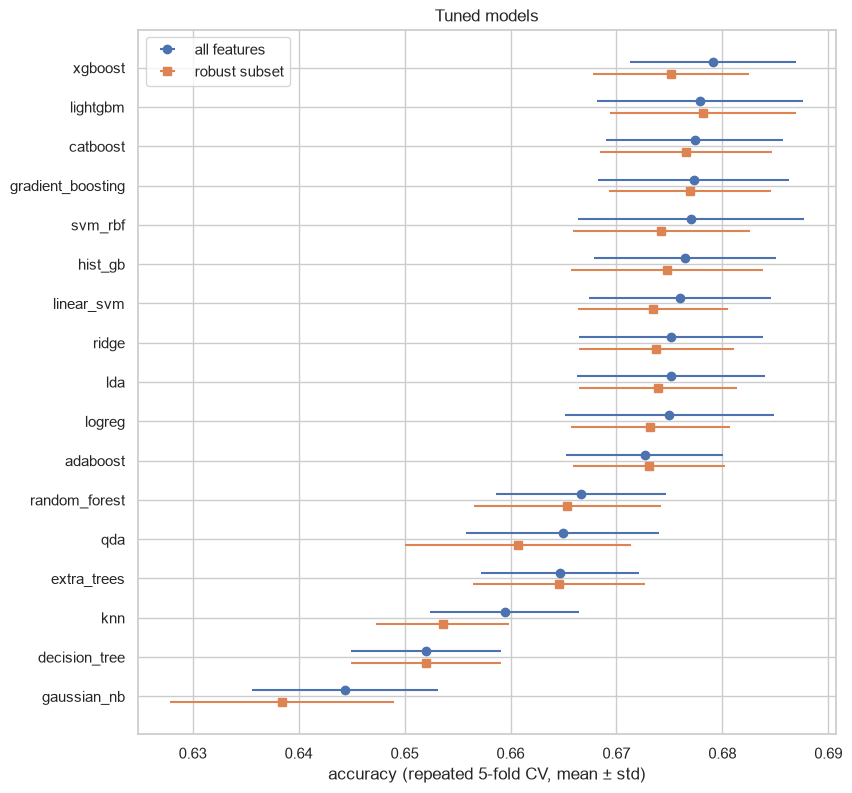

In [9]:
rep = pd.DataFrame(evals).T.sort_values('rep_mean_all')
fig, ax = plt.subplots(figsize=(9, 0.45 * len(rep) + 1.5))
pos = np.arange(len(rep))
ax.errorbar(rep['rep_mean_all'].astype(float), pos + 0.15, xerr=rep['rep_std_all'].astype(float), fmt='o', label='all features')
ax.errorbar(rep['rep_mean_robust'].astype(float), pos - 0.15, xerr=rep['rep_std_robust'].astype(float), fmt='s', label='robust subset')
ax.set_yticks(pos)
ax.set_yticklabels(rep.index)
ax.set_xlabel('accuracy (repeated 5-fold CV, mean ± std)')
ax.set_title('Tuned models')
ax.legend()
plt.show()

## 5. Stress test: P2's KOs recorded differently

The final evaluation set is private and may record P2's KOs differently from our data. We train on clean
folds and validate on folds where a fraction (50% / 100%) of P2's Pokémon that vanished with HP ≤ 0.5 are
turned into recorded KOs (`src/validation.py`, `perturb_p2_ko`). A robust model loses little accuracy.
The robust subset is unaffected by construction (it has none of the perturbed features).

In [10]:
for name, t in tuned.items():
    t0 = time.time()
    st = stress_test(with_params(specs[name], t['params']), X_all, y)
    evals[name].update({'stress_clean': st['clean'], 'stress_fixed_50': st['p2_ko_fixed_0.5'],
                        'stress_fixed_100': st['p2_ko_fixed_1'],
                        'stress_drop_points': (st['clean'] - st['p2_ko_fixed_1']) * 100})
    print(f"{name:18s} clean {st['clean']:.4f} | 50% fixed {st['p2_ko_fixed_0.5']:.4f} | "
          f"100% fixed {st['p2_ko_fixed_1']:.4f}  ({time.time() - t0:6.1f}s)")

logreg             clean 0.6778 | 50% fixed 0.6741 | 100% fixed 0.6721  (   0.5s)
ridge              clean 0.6777 | 50% fixed 0.6745 | 100% fixed 0.6722  (   0.4s)
linear_svm         clean 0.6778 | 50% fixed 0.6727 | 100% fixed 0.6708  (   1.6s)
lda                clean 0.6780 | 50% fixed 0.6744 | 100% fixed 0.6717  (   0.4s)
qda                clean 0.6673 | 50% fixed 0.6650 | 100% fixed 0.6635  (   0.8s)
gaussian_nb        clean 0.6442 | 50% fixed 0.6439 | 100% fixed 0.6417  (   0.4s)
knn                clean 0.6602 | 50% fixed 0.6571 | 100% fixed 0.6556  (   4.7s)
svm_rbf            clean 0.6795 | 50% fixed 0.6754 | 100% fixed 0.6721  (  22.9s)
decision_tree      clean 0.6531 | 50% fixed 0.6531 | 100% fixed 0.6531  (   0.6s)
random_forest      clean 0.6696 | 50% fixed 0.6698 | 100% fixed 0.6710  ( 103.4s)
extra_trees        clean 0.6668 | 50% fixed 0.6669 | 100% fixed 0.6673  (  51.7s)
adaboost           clean 0.6731 | 50% fixed 0.6741 | 100% fixed 0.6753  ( 273.9s)
gradient_boostin

## 6. Ensembles of the top models

- **Soft voting**: average of the predicted probabilities of the top-K tuned models that have `predict_proba`.
- **Stacking**: the top-K tuned models (any kind) feed a logistic meta-model trained on out-of-fold
  predictions (internal 5-fold CV), so the meta-model never sees predictions made on its own training rows.

In [11]:
ranking = sorted(evals, key=lambda n: evals[n]['rep_mean_all'], reverse=True)
top_proba = [n for n in ranking if specs[n].has_proba][:TOP_K]
top_any = ranking[:TOP_K]
print('soft voting members:', top_proba)
print('stacking members:   ', top_any)

def members(model_names):
    return [(n, with_params(specs[n], tuned[n]['params'])) for n in model_names]

ensembles = {'ens_soft_voting': (VotingClassifier(members(top_proba), voting='soft', n_jobs=1), top_proba)}
if RUN_STACKING:
    stack = StackingClassifier(members(top_any), final_estimator=LogisticRegression(C=1.0, max_iter=2000),
                               cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=1)
    ensembles['ens_stacking'] = (stack, top_any)

for name, (model, used) in ensembles.items():
    t0 = time.time()
    m_all, s_all = repeated_cv(model, X_all, y)
    m_rob, s_rob = repeated_cv(model, X_robust, y)
    st = stress_test(model, X_all, y)
    evals[name] = {'family': 'ensemble', 'rep_mean_all': m_all, 'rep_std_all': s_all,
                   'rep_mean_robust': m_rob, 'rep_std_robust': s_rob,
                   'stress_clean': st['clean'], 'stress_fixed_50': st['p2_ko_fixed_0.5'],
                   'stress_fixed_100': st['p2_ko_fixed_1'],
                   'stress_drop_points': (st['clean'] - st['p2_ko_fixed_1']) * 100,
                   'params_text': 'members: ' + ', '.join(used)}
    print(f'{name:18s} all {m_all:.4f} ± {s_all:.4f} | robust {m_rob:.4f} ± {s_rob:.4f}  ({time.time() - t0:6.1f}s)')

soft voting members: ['xgboost', 'lightgbm', 'catboost', 'gradient_boosting']
stacking members:    ['xgboost', 'lightgbm', 'catboost', 'gradient_boosting']
ens_soft_voting    all 0.6800 ± 0.0080 | robust 0.6795 ± 0.0078  ( 482.2s)
ens_stacking       all 0.6795 ± 0.0081 | robust 0.6787 ± 0.0077  (2479.9s)


## 7. Nested CV of the top 3 models (optional)

The search score and the repeated CV reuse the data the parameters were tuned on, so they are slightly
optimistic. Nested CV repeats the whole search inside each outer fold (outer seed 7) and scores the chosen
model on the outer validation fold only: an unbiased estimate, worth reporting. Enable with `RUN_NESTED_CV`.

In [15]:
if RUN_NESTED_CV:
    outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
    for name in [n for n in ranking if n in tuned][:3]:
        t0 = time.time()
        scores = []
        for tr, va in outer.split(X_all, y):
            search = tune(specs[name], X_all.iloc[tr], y.iloc[tr], CV, n_iter_scale=N_ITER_SCALE, n_jobs=N_JOBS)
            params, _, _ = best_from_search(search)
            fitted = with_params(specs[name], params).fit(X_all.iloc[tr], y.iloc[tr])
            scores.append((fitted.predict(X_all.iloc[va]) == y.iloc[va]).mean())
        evals[name]['nested_mean'] = float(np.mean(scores))
        evals[name]['nested_std'] = float(np.std(scores))
        print(f'{name:18s} nested CV {np.mean(scores):.4f} ± {np.std(scores):.4f}  ({time.time() - t0:6.1f}s)')
else:
    print('nested CV skipped (RUN_NESTED_CV = False)')

xgboost            nested CV 0.6751 ± 0.0071  ( 477.7s)
lightgbm           nested CV 0.6781 ± 0.0083  ( 330.2s)
catboost           nested CV 0.6792 ± 0.0070  (1037.4s)


## 8. Summary: best models and best parameters

Sorted by repeated-CV accuracy on all features. Columns:
- `default` / `tuned (seed 42)`: 5-fold CV before and after the search (the tuned score is optimistic);
- `repeated CV all` / `repeated CV robust`: mean ± std over 3 seeds × 5 folds;
- `stress drop`: accuracy points lost when 100% of P2's vanished low-HP Pokémon are recorded as KOs;
- `nested CV`: only if enabled;
- `best parameters`: from the search (members for the ensembles).

In [16]:
default_score = screen.set_index('model')['cv_mean'].to_dict()
rows = []
for name, e in evals.items():
    t = tuned.get(name, {})
    rows.append({
        'model': name,
        'family': e['family'],
        'default': default_score.get(name, np.nan),
        'tuned (seed 42)': t.get('tune_mean', np.nan),
        'rep_mean_all': e['rep_mean_all'],
        'rep_mean_robust': e['rep_mean_robust'],
        'repeated CV all': f"{e['rep_mean_all']:.4f} ± {e['rep_std_all']:.4f}",
        'repeated CV robust': f"{e['rep_mean_robust']:.4f} ± {e['rep_std_robust']:.4f}",
        'stress drop': e.get('stress_drop_points', np.nan),
        'nested CV': e.get('nested_mean', np.nan),
        'search time (min)': t.get('time_s', np.nan) / 60,
        'best parameters': e['params_text'],
    })

summary = pd.DataFrame(rows).sort_values('rep_mean_all', ascending=False).reset_index(drop=True)
summary.index = summary.index + 1
summary.drop(columns=['rep_mean_all', 'rep_mean_robust']).to_csv(OUT / 'summary.csv', index_label='rank')

table = summary.drop(columns=['rep_mean_all', 'rep_mean_robust', 'best parameters'])
print('=' * 120)
print('MODEL COMPARISON (train only, accuracy)')
print('=' * 120)
print(table.to_string(float_format=lambda v: f'{v:.4f}'))

print()
print('=' * 120)
print('BEST PARAMETERS (ranked)')
print('=' * 120)
for rank, row in summary.iterrows():
    print(f"{rank:2d}. {row['model']:18s} {row['repeated CV all']}  ->  {row['best parameters']}")

best = summary.iloc[0]
best_single = summary[summary['family'] != 'ensemble'].iloc[0]
best_robust = summary.sort_values('rep_mean_robust', ascending=False).iloc[0]
print()
print(f"best overall:       {best['model']} ({best['repeated CV all']})")
print(f"best single model:  {best_single['model']} ({best_single['repeated CV all']})")
print(f"best robust subset: {best_robust['model']} ({best_robust['repeated CV robust']})")
print(f'saved: {OUT / "summary.csv"} and {OUT / "best_params.json"}')

MODEL COMPARISON (train only, accuracy)
                model        family  default  tuned (seed 42)  repeated CV all repeated CV robust  stress drop  nested CV  search time (min)
1     ens_soft_voting      ensemble      NaN              NaN  0.6800 ± 0.0080    0.6795 ± 0.0078       0.0000        NaN                NaN
2        ens_stacking      ensemble      NaN              NaN  0.6795 ± 0.0081    0.6787 ± 0.0077       0.0100        NaN                NaN
3             xgboost      boosting   0.6557           0.6828  0.6791 ± 0.0078    0.6752 ± 0.0074       0.1200     0.6751             1.8454
4            lightgbm      boosting   0.6713           0.6798  0.6779 ± 0.0097    0.6782 ± 0.0088       0.0400     0.6781             1.3674
5            catboost      boosting   0.6787           0.6809  0.6774 ± 0.0084    0.6765 ± 0.0081      -0.1500     0.6792             3.5777
6   gradient_boosting      boosting   0.6761           0.6785  0.6773 ± 0.0090    0.6769 ± 0.0077       0.1200    

## Next steps

- Record the results in `EXPERIMENTS.md` (summary row + one card per model family, negative results included).
- Pick the 3 final submissions with **different** profiles: best ensemble, best single model, and a prudent
  model on the robust subset (low stress drop).
- The submission notebook reads `data/processed/models/best_params.json`, refits the chosen models on the whole
  training set and predicts `features_test.pkl`.